The goal of this assignment is to practice conducting robot simulations using PyBullet.

This HW borrows from: [PyBullet Official Tutorial](https://github.com/bulletphysics/bullet3/blob/master/examples/pybullet/notebooks/HelloPyBullet.ipynb)

You may find this to be a helpful reference: [PyBullet Quickstart Guide](https://github.com/bulletphysics/bullet3/blob/master/docs/pybullet_quickstartguide.pdf)

# Preliminaries

We've set up the environment for you, but you should read this code closely, as it will help you with later parts.

One important point to note is that when running any pybullet method (`p.method()`), you should always include the `sim_id` if the argument is taken. Otherwise, the method may not be applied to the current simulation.

In [1]:
# Run once at the beginning to install pybullet
!pip install pybullet

In [2]:
# imports
import os
import pybullet as p
import numpy as np
from matplotlib import pyplot as plt

In [3]:
# Set up the simulation
sim_id = p.connect(p.DIRECT)

In [4]:
# PyBullet has a lot of built-in data (e.g., robor models), so let's get access to it
import pybullet_data
p.setAdditionalSearchPath(pybullet_data.getDataPath())

In [5]:
p.resetSimulation(physicsClientId=sim_id)

data_path = pybullet_data.getDataPath()

plane_id = p.loadURDF(os.path.join(data_path, 'plane.urdf'),
            physicsClientId=sim_id)

robot_id = p.loadURDF(os.path.join(data_path, "kuka_iiwa/model.urdf"),
            basePosition=[0,0,0],
            baseOrientation=p.getQuaternionFromEuler([0,0,0]),
            useFixedBase=True,
            globalScaling=1,
            flags=p.URDF_USE_IMPLICIT_CYLINDER,
            physicsClientId=sim_id)

cube_id = p.loadURDF(os.path.join(data_path, 'cube.urdf'),
            basePosition=[0.5, 0, 0.5],
            globalScaling=0.2,
            physicsClientId=sim_id)

sphere_id = p.loadURDF(os.path.join(data_path, 'sphere2.urdf'),
            basePosition=[0, 0.5, 0.5],
            globalScaling=0.2,
            physicsClientId=sim_id)

num_bodies = p.getNumBodies(physicsClientId=sim_id)

assert num_bodies == 4, f"Expected 4 bodies to be loaded, but got {num_bodies}"

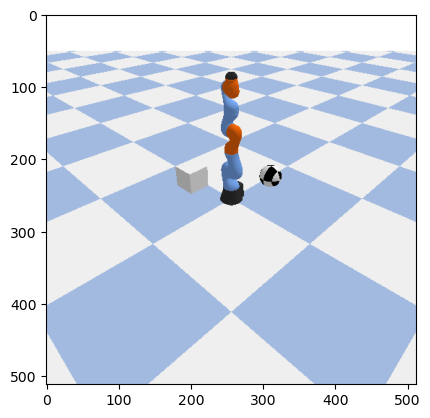

In [6]:
# We can inspect some images, as a sanity check:
def showImage(cameraPos=[2, 2, 2]):
  viewMatrix = p.computeViewMatrix(
              cameraEyePosition=cameraPos,
              cameraTargetPosition=[0, 0, 0],
              cameraUpVector=[0, 0, 1],
              physicsClientId=sim_id)
  projectionMatrix = p.computeProjectionMatrixFOV(
              fov=60.0,
              aspect=1.0,
              nearVal=0.1,
              farVal=10,
              physicsClientId=sim_id)
  width, height, rgbImg, depthImg, segImg = p.getCameraImage(
              width=512,
              height=512,
              viewMatrix=viewMatrix,
              projectionMatrix=projectionMatrix,
              physicsClientId=sim_id)
  plt.imshow(rgbImg)

showImage()

# Part 1: Homogeneous Transformations

For our first set of tasks, we will be locating and moving objects around relative to different frames. Recall that a homogeneous transformation matrix $T \in SE(3)$ unifies rotation $R \in SO(3)$ and translation $p \in \mathbb{R}^3$ into a single $4 \times 4$ matrix:

$$T = \begin{bmatrix} R & p \\ 0_{1 \times 3} & 1 \end{bmatrix} = \begin{bmatrix} r_{11} & r_{12} & r_{13} & x \\ r_{21} & r_{22} & r_{23} & y \\ r_{31} & r_{32} & r_{33} & z \\ 0 & 0 & 0 & 1 \end{bmatrix}$$

## 1.1: Manual Pose Assignment (4 pts)

Suppose we want to set the cube's pose to the following relative to the world frame:
   * Translation: $p = [0.5, 0.2, 0.5]$
   * Rotation: $45^\circ$ ($\frac\pi4\text{ rad}$) around the Z-axis. This can first be specified as an array of $xyz$ Euler angles.

Update the cube's pose in PyBullet using `p.resetBasePositionAndOrientation()`. Note that it takes in four arguments: the `cube_id`, position, the *quaternion* representation of the Euler angles, and the `sim_id`. You can use `p.getQuaternionFromEuler()` to compute the third argument, as done in the loading of the robot above.

In [7]:
cube_position = [0.5, 0.2, 0.5]
cube_euler = [0.0, 0.0, np.pi / 4]
cube_quaternion = p.getQuaternionFromEuler(cube_euler)
p.resetBasePositionAndOrientation(
    cube_id, cube_position, cube_quaternion, physicsClientId=sim_id
)

If you successfully completed this task, the following code should show the cube in its new pose.

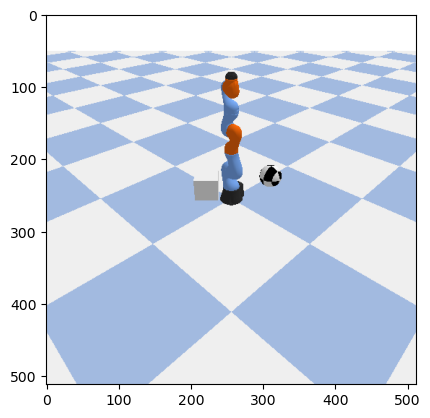

In [8]:
showImage()

## 1.2: Frame Transformations (8 pts)

Now suppose we are interested in transforming points on the cube from its body frame into the global world frame. To do so, we will need to formulate the corresponding homogeneous transformation matrix $T^{world}_{cube}$.

First, complete the method `pose_to_matrix()`, which takes in a position and Euler angles and returns a $4 \times 4$ array representing the homogeneous transformation. You can convert Euler angles into a rotation matrix using the `from_euler()` method of `R`.

Using the matrix returned by this method, compute the world coordinates of the corner of the cube located at $p_{cube} = [0.1, 0.1, 0.1, 1.0]^T$ (in body coordinates).

In [9]:
from scipy.spatial.transform import Rotation as R

def pose_to_matrix(position, orientation_euler):
    T = np.eye(4)
    T[:3, :3] = R.from_euler('xyz', orientation_euler).as_matrix()
    T[:3, 3] = np.asarray(position, dtype=float)
    return T

In [10]:
T_world_cube = pose_to_matrix(cube_position, cube_euler)
p_cube = np.array([0.1, 0.1, 0.1, 1.0])
p_world_homogeneous = T_world_cube @ p_cube
p_world = p_world_homogeneous[:3]

In [11]:
expected_p_world = np.array([0.5, 0.3414213562373095, 0.6])
assert np.allclose(p_world, expected_p_world, atol=1e-6)

## 1.3: Composing Transformations (8 pts)

Finally, suppose we are tasked to reset the sphere's pose relative to the *cube*'s frame as follows:
   * Translation: $p = [0.4, 0, 0]$
   * Rotation: $30^\circ$ ($\frac\pi6\text{ rad}$) around the Y-axis.

To do so, you will first need to compute the homogeneous transformation $T^{cube}_{sphere}$. Next, perform the appropriate composition to find $T^{world}_{sphere}$. Finally, extract the resultant pose and apply it to the sphere.

In [12]:
T_cube_sphere = pose_to_matrix([0.4, 0.0, 0.0], [0.0, np.pi / 6, 0.0])
T_world_sphere = T_world_cube @ T_cube_sphere

sphere_position = T_world_sphere[:3, 3]
sphere_quaternion = R.from_matrix(T_world_sphere[:3, :3]).as_quat()
p.resetBasePositionAndOrientation(
    sphere_id, sphere_position, sphere_quaternion, physicsClientId=sim_id
)

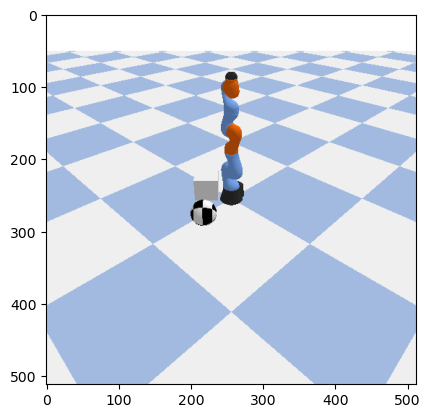

In [13]:
showImage()

# Part 2: C-Space and Collision Modeling

We will now work with the robot and develop a (partial) visualization of its C-space. We will first reset the cube and sphere to their original poses.

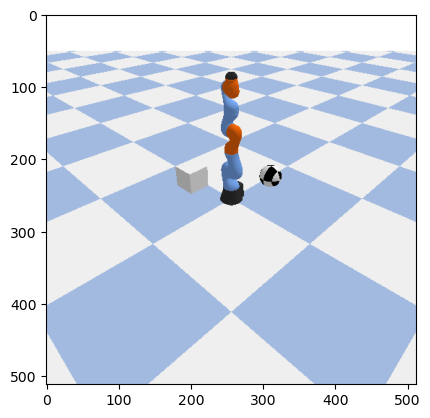

In [14]:
zero = p.getQuaternionFromEuler([0, 0, 0])
p.resetBasePositionAndOrientation(cube_id, [0.5, 0, 0.5], zero, physicsClientId=sim_id)
p.resetBasePositionAndOrientation(sphere_id, [0, 0.5, 0.5], zero, physicsClientId=sim_id)
showImage()

## 2.1: Global Collision Detector (4 pts)

The first task will be to implement a Boolean method checking for a collision between a robot and any other object, excluding the ground.

First, call `p.performCollisionDetection()` to run PyBullet's collision detection algorithm.

The relevant information can then be retrieved using `p.getContactPoints()` and the `robot_id`, which returns a list of contact point tuples. For each one, you will want to check that 1) the contacting body is any object but the ground plane, and 2) the penetration distance is negative.

If both conditions hold true for at least one contact point, then return True. Otherwise, return False.

In [15]:
def is_collision():
    p.performCollisionDetection(physicsClientId=sim_id)
    contacts = p.getContactPoints(bodyA=robot_id, physicsClientId=sim_id)
    for contact in contacts:
        if contact[2] != plane_id and contact[8] < 0:
            return True
    return False

If you implemented the method correctly, the following assertion should pass (as evidenced by the lack of collisions in the image above).

In [16]:
assert not is_collision()

## 2.2: Setting Joint Positions (4 pts)

We will next require a method to set the robot's joints to specific values within a valid range. Write a method that sets the first two joints of the robot to `theta0` and `theta1`, respectively. Suppose that the robot also has joint limits, which will be $\pm \frac{3\pi}{4}$ for `theta0` and $\pm \frac{2\pi}{3}$ for `theta1`. If values outside these ranges are inputted to the method, it should raise a ValueError. Otherwise, you can use `p.resetJointState()` to perform the task.

In [17]:
def setRobotPos(theta0, theta1):
    theta0_limit = 3 * np.pi / 4
    theta1_limit = 2 * np.pi / 3
    if not (-theta0_limit <= theta0 <= theta0_limit):
        raise ValueError(f'theta0 must be in [-3pi/4, 3pi/4], got {theta0}')
    if not (-theta1_limit <= theta1 <= theta1_limit):
        raise ValueError(f'theta1 must be in [-2pi/3, 2pi/3], got {theta1}')
    p.resetJointState(robot_id, 0, theta0, physicsClientId=sim_id)
    p.resetJointState(robot_id, 1, theta1, physicsClientId=sim_id)

Unit test to make sure your method properly catches out of bounds inputs.

In [18]:
try:
    setRobotPos(np.pi * 3 / 4 + 0.00001, -np.pi * 2 / 3 - 0.00001)
    assert False
except ValueError as e:
    pass

The following commands should show an image of the robot pointing at you, along with verifying no collision.

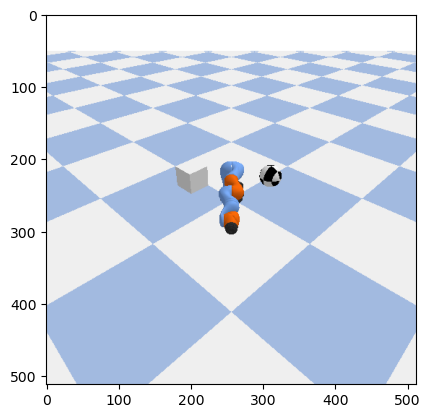

In [19]:
setRobotPos(np.pi/4, np.pi*1/2)
assert not is_collision()
showImage()

The following commands should show an image of the robot touching the ball, along with verifying a collision.

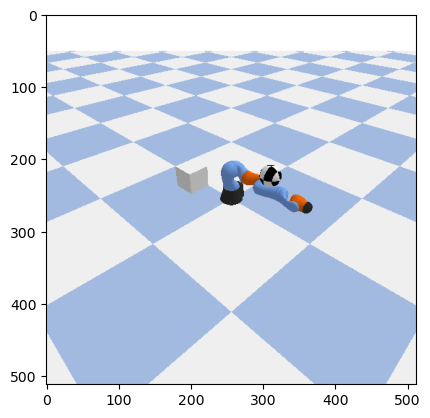

In [20]:
setRobotPos(np.pi/2, np.pi*1/2)
assert is_collision()
showImage()

## 2.3: Flattened C-Space (8 pts)

Your last two tasks will be to generate visualizations of the robot's configuration space in its first two joints using a sampling-based approach.

First write a method that shows a "flattened" C-space on a $\theta_0$- $\theta_1$ plane. Generate a scatter plot of `num_samples` samples within the valid region. Plot free space and obstacle region samples using different colors, and show a legend indicating which is which.

In [21]:
def flattened_cspace(num_samples):
    if not isinstance(num_samples, (int, np.integer)) or num_samples <= 0:
        raise ValueError('num_samples must be a positive integer')

    rng = np.random.default_rng(0)
    theta0 = rng.uniform(-3 * np.pi / 4, 3 * np.pi / 4, num_samples)
    theta1 = rng.uniform(-2 * np.pi / 3, 2 * np.pi / 3, num_samples)
    collisions = np.empty(num_samples, dtype=bool)

    old_theta0 = p.getJointState(robot_id, 0, physicsClientId=sim_id)[0]
    old_theta1 = p.getJointState(robot_id, 1, physicsClientId=sim_id)[0]
    try:
        for i, (th0, th1) in enumerate(zip(theta0, theta1)):
            setRobotPos(th0, th1)
            collisions[i] = is_collision()
    finally:
        setRobotPos(old_theta0, old_theta1)

    free = ~collisions

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(theta0[free], theta1[free], s=7, c='tab:blue', alpha=0.65, label='Free')
    ax.scatter(theta0[collisions], theta1[collisions], s=7, c='tab:red', alpha=0.75, label='Collision')
    ax.set(xlabel=r'$\theta_0$ (rad)', ylabel=r'$\theta_1$ (rad)',
           title='Sampled configuration space')
    ax.set_xlim(-3 * np.pi / 4, 3 * np.pi / 4)
    ax.set_ylim(-2 * np.pi / 3, 2 * np.pi / 3)
    ax.grid(alpha=0.2)
    ax.legend()
    plt.show()

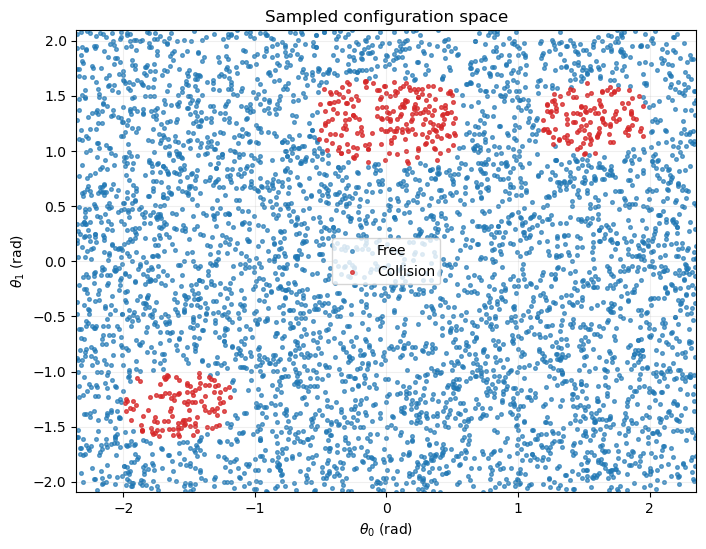

In [22]:
flattened_cspace(5000)

## 2.4: Embedded C-Space (14 pts)

Now write a method that shows the robot's C-space as a torus embedded in 3D space. You may find the torus [equations](https://en.wikipedia.org/wiki/Torus#Geometry) to be helpful. Note that the *size* (radii) of the torus is not important; you can choose values that produce a good visualization. Also note that the result should be a *partial* torus due to the joint limits.

As in above, plot free space and obstacle region samples using different colors, and show a legend indicating which is which.

In [23]:
def cspace(num_samples):
    if not isinstance(num_samples, (int, np.integer)) or num_samples <= 0:
        raise ValueError('num_samples must be a positive integer')

    rng = np.random.default_rng(0)
    theta0 = rng.uniform(-3 * np.pi / 4, 3 * np.pi / 4, num_samples)
    theta1 = rng.uniform(-2 * np.pi / 3, 2 * np.pi / 3, num_samples)
    collisions = np.empty(num_samples, dtype=bool)

    old_theta0 = p.getJointState(robot_id, 0, physicsClientId=sim_id)[0]
    old_theta1 = p.getJointState(robot_id, 1, physicsClientId=sim_id)[0]
    try:
        for i, (th0, th1) in enumerate(zip(theta0, theta1)):
            setRobotPos(th0, th1)
            collisions[i] = is_collision()
    finally:
        setRobotPos(old_theta0, old_theta1)

    free = ~collisions

    major_radius, minor_radius = 3.0, 1.0
    x = (major_radius + minor_radius * np.cos(theta1)) * np.cos(theta0)
    y = (major_radius + minor_radius * np.cos(theta1)) * np.sin(theta0)
    z = minor_radius * np.sin(theta1)

    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(x[free], y[free], z[free], s=7, c='tab:blue', alpha=0.55, label='Free')
    ax.scatter(x[collisions], y[collisions], z[collisions], s=7, c='tab:red', alpha=0.8, label='Collision')
    ax.set(xlabel='x', ylabel='y', zlabel='z', title='Configuration space embedded as a partial torus')
    ax.set_box_aspect((1, 1, 0.45))
    ax.legend()
    plt.show()

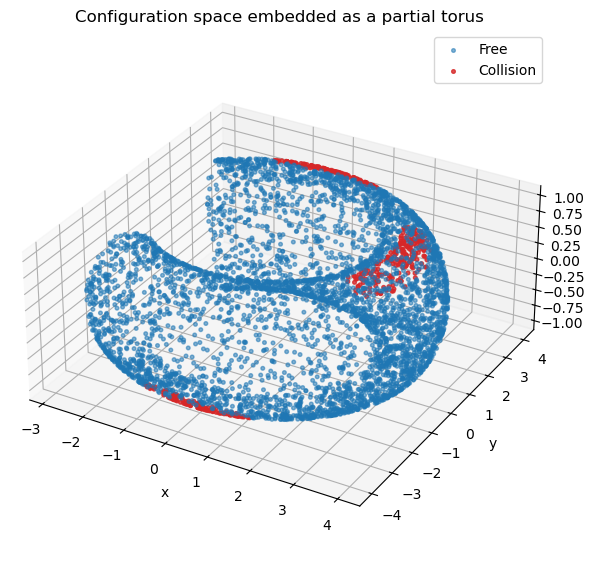

In [24]:
cspace(5000)

\newpage

## References

1. Bullet Physics SDK. [*HelloPyBullet* Jupyter Notebook](https://github.com/bulletphysics/bullet3/blob/master/examples/pybullet/notebooks/HelloPyBullet.ipynb).
2. Coumans, E., and Bai, Y. [*PyBullet Quickstart Guide*](https://github.com/bulletphysics/bullet3/blob/master/docs/pybullet_quickstartguide.pdf). Bullet Physics SDK.
3. SciPy Developers. [`scipy.spatial.transform.Rotation.from_matrix`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.transform.Rotation.from_matrix.html). SciPy Reference Guide.
4. SciPy Developers. [`scipy.spatial.transform.Rotation.as_quat`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.transform.Rotation.as_quat.html). SciPy Reference Guide.
5. OpenAI. [*Codex*](https://openai.com/codex/). Used to assist with notebook-to-PDF file conversion and document formatting.